<a href="https://colab.research.google.com/github/AnjanaVP231/ML/blob/main/lab8_CCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 10 records:
         X1         X2        X3        X4        Y1        Y2         Y3
0  1.971241   6.702125  0.410195 -2.712593 -0.770524 -3.062638   2.764469
1  0.815338   7.985222  1.576354 -2.406596 -3.673239 -4.694017  14.104524
2 -0.693237   9.655552 -0.566316  1.079341  0.162747 -0.323253   0.121652
3 -0.006933   0.327976  0.211015  0.839060 -0.323253  0.198880  -0.391015
4 -4.003556  11.034649 -1.420485  2.673175  3.537477  1.554290  -1.351532
5  0.321971  -6.818027 -0.975308 -0.039113 -1.435207  1.886911  -3.550842
6  3.149302  -4.244258  1.330710 -1.918998 -2.501693 -2.921395   3.870522
7  0.641964   1.366539  0.533052 -0.787973 -0.939810 -0.732898  -2.359760
8  1.758616  -3.992942  0.862967 -3.431079 -2.515359 -1.021398   4.639580
9  0.443252  -1.753928  0.247372 -1.139232 -1.784406 -0.946722  -0.581214

Dataset shape: (240, 7)

Column names: ['X1', 'X2', 'X3', 'X4', 'Y1', 'Y2', 'Y3']

Descriptive statistics:
               X1          X2          X3          X4       

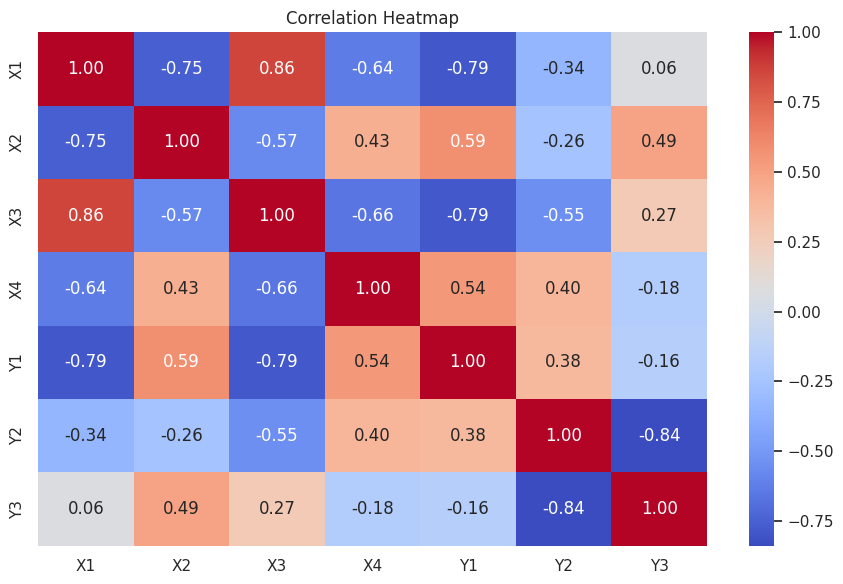


Cross-set Pearson correlation matrix:
          Y1        Y2        Y3
X1 -0.790248 -0.336484  0.059521
X2  0.587891 -0.256182  0.490139
X3 -0.786104 -0.547028  0.272353
X4  0.542177  0.398728 -0.184006


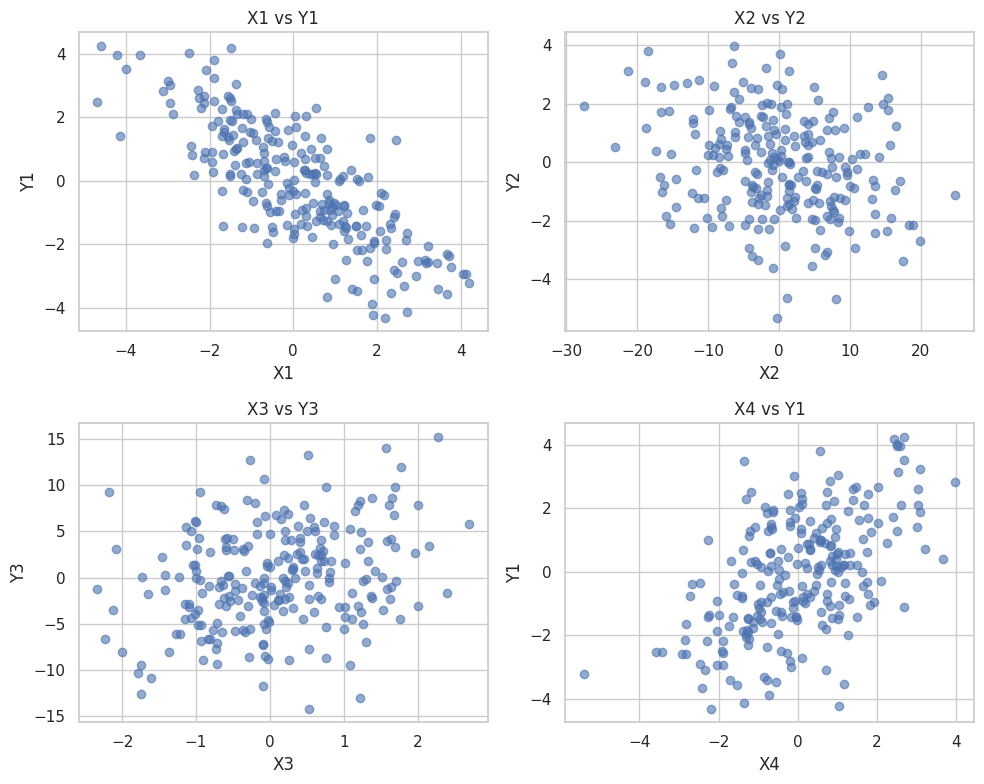


Training canonical correlations:
[np.float64(0.92238239446462), np.float64(0.8326161646330531), np.float64(0.1159576352788682)]

Testing canonical correlations:
[np.float64(0.8932201511028247), np.float64(0.8234981863259687), np.float64(-0.17163134105910954)]


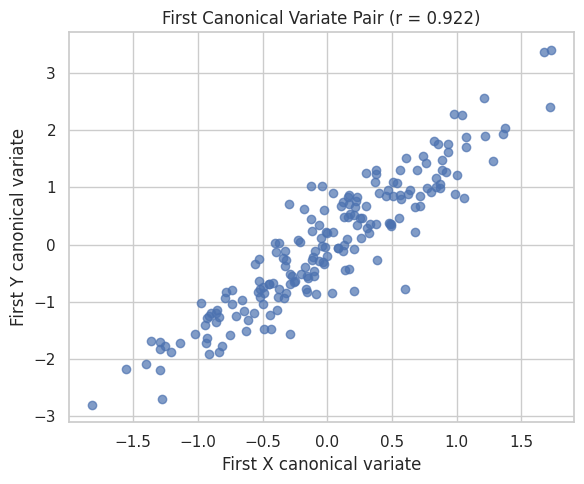

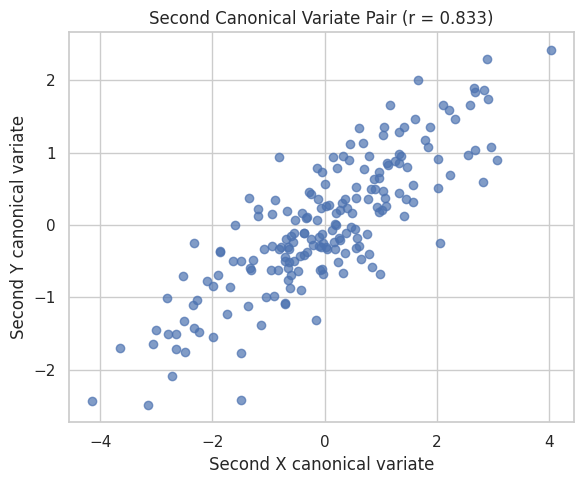


Canonical correlation comparison:
  Component  Training   Testing
0       CC1  0.922382  0.893220
1       CC2  0.832616  0.823498
2       CC3  0.115958 -0.171631

Original pairwise correlations:
          Y1        Y2        Y3
X1 -0.790248 -0.336484  0.059521
X2  0.587891 -0.256182  0.490139
X3 -0.786104 -0.547028  0.272353
X4  0.542177  0.398728 -0.184006

First canonical correlation: 0.92238239446462

CCA X weights:
         CC1       CC2       CC3
X1  0.428444 -0.507465 -0.200444
X2  0.768463  0.636600  0.064190
X3  0.471394 -0.580065  0.200802
X4 -0.060732 -0.027283  0.956755

CCA Y weights:
         CC1       CC2       CC3
Y1 -0.155018  0.797421 -0.583172
Y2 -0.978772 -0.043860  0.200202
Y3  0.134068  0.601827  0.787293

X canonical loadings:
         CC1       CC2       CC3
X1  0.421423 -0.873411 -0.025675
X2  0.222104  0.973835  0.048014
X3  0.650215 -0.728055  0.040363
X4 -0.429012  0.509574  0.739715

Y canonical loadings:
         CC1       CC2       CC3
Y1 -0.464593  0.843

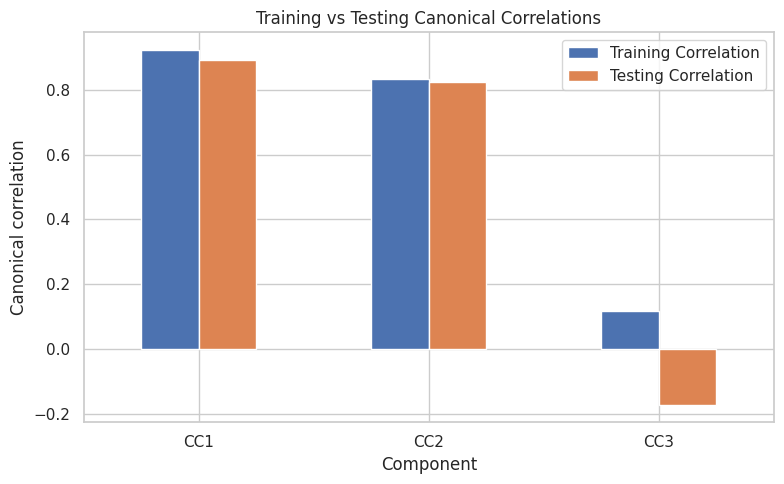

In [ ]:
# Task 1: Load and understand the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import CCA

df = pd.read_csv("CCA_Dataset.csv")

print("First 10 records:")
print(df.head(10))

print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nDescriptive statistics:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Identify the two variable sets
X_cols = ["X1", "X2", "X3", "X4"]
Y_cols = ["Y1", "Y2", "Y3"]

# Remove rows with missing values before analysis
df = df.dropna(subset=X_cols + Y_cols).drop_duplicates()

X = df[X_cols]
Y = df[Y_cols]

# Correlation heatmap for all seven variables
plt.figure(figsize=(9, 6))
sns.heatmap(df[X_cols + Y_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# Task 2: Explore relationships between the two sets

cross_corr = df[X_cols].corrwith(df[Y_cols[0]])  # Initial check
cross_corr = df[X_cols + Y_cols].corr().loc[X_cols, Y_cols]

print("\nCross-set Pearson correlation matrix:")
print(cross_corr)

# Scatter plots of selected cross-set relationships
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

pairs = [("X1", "Y1"), ("X2", "Y2"), ("X3", "Y3"), ("X4", "Y1")]

for ax, (x_col, y_col) in zip(axes.flat, pairs):
    ax.scatter(df[x_col], df[y_col], alpha=0.6)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(f"{x_col} vs {y_col}")

plt.tight_layout()
plt.show()

# Individual pairwise correlations may not reveal relationships involving
# combinations of variables from both sets. CCA finds linear combinations
# of X and Y that maximize their correlation.


# Task 3: Apply Canonical Correlation Analysis

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

# Fit separate scalers using training data only
scaler_X = StandardScaler()
scaler_Y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

Y_train_scaled = scaler_Y.fit_transform(Y_train)
Y_test_scaled = scaler_Y.transform(Y_test)

# Maximum components cannot exceed the smaller variable-set size;
# deficient matrix rank can reduce the effective number of components.
n_components = min(3, len(X_cols), len(Y_cols))

cca = CCA(n_components=n_components, max_iter=1000)
cca.fit(X_train_scaled, Y_train_scaled)

X_train_cca, Y_train_cca = cca.transform(X_train_scaled, Y_train_scaled)
X_test_cca, Y_test_cca = cca.transform(X_test_scaled, Y_test_scaled)

# Calculate correlations between corresponding canonical variates
train_corr = [
    np.corrcoef(X_train_cca[:, i], Y_train_cca[:, i])[0, 1]
    for i in range(n_components)
]

test_corr = [
    np.corrcoef(X_test_cca[:, i], Y_test_cca[:, i])[0, 1]
    for i in range(n_components)
]

print("\nTraining canonical correlations:")
print(train_corr)

print("\nTesting canonical correlations:")
print(test_corr)


# Task 4: Visualize and interpret canonical variates

plt.figure(figsize=(6, 5))
plt.scatter(X_train_cca[:, 0], Y_train_cca[:, 0], alpha=0.7)
plt.xlabel("First X canonical variate")
plt.ylabel("First Y canonical variate")
plt.title(f"First Canonical Variate Pair (r = {train_corr[0]:.3f})")
plt.tight_layout()
plt.show()

# Plot the second pair when available
if n_components >= 2:
    plt.figure(figsize=(6, 5))
    plt.scatter(X_train_cca[:, 1], Y_train_cca[:, 1], alpha=0.7)
    plt.xlabel("Second X canonical variate")
    plt.ylabel("Second Y canonical variate")
    plt.title(f"Second Canonical Variate Pair (r = {train_corr[1]:.3f})")
    plt.tight_layout()
    plt.show()

print("\nCanonical correlation comparison:")
print(pd.DataFrame({
    "Component": [f"CC{i+1}" for i in range(n_components)],
    "Training": train_corr,
    "Testing": test_corr
}))

# Compare CC1 with original pairwise correlations
print("\nOriginal pairwise correlations:")
print(cross_corr)

print("\nFirst canonical correlation:", train_corr[0])


# Task 5: Examine canonical weights and loadings

print("\nCCA X weights:")
print(pd.DataFrame(
    cca.x_weights_,
    index=X_cols,
    columns=[f"CC{i+1}" for i in range(n_components)]
))

print("\nCCA Y weights:")
print(pd.DataFrame(
    cca.y_weights_,
    index=Y_cols,
    columns=[f"CC{i+1}" for i in range(n_components)]
))

# Canonical loadings: correlations between original standardized variables
# and their corresponding canonical variates.
x_loadings = np.column_stack([
    [np.corrcoef(X_train_scaled[:, j], X_train_cca[:, i])[0, 1]
     for j in range(len(X_cols))]
    for i in range(n_components)
])

y_loadings = np.column_stack([
    [np.corrcoef(Y_train_scaled[:, j], Y_train_cca[:, i])[0, 1]
     for j in range(len(Y_cols))]
    for i in range(n_components)
])

print("\nX canonical loadings:")
print(pd.DataFrame(
    x_loadings,
    index=X_cols,
    columns=[f"CC{i+1}" for i in range(n_components)]
))

print("\nY canonical loadings:")
print(pd.DataFrame(
    y_loadings,
    index=Y_cols,
    columns=[f"CC{i+1}" for i in range(n_components)]
))

print("\nStrongest X variables for CC1:")
print(pd.Series(x_loadings[:, 0], index=X_cols).abs().sort_values(ascending=False))

print("\nStrongest Y variables for CC1:")
print(pd.Series(y_loadings[:, 0], index=Y_cols).abs().sort_values(ascending=False))

# Weights define the linear combinations; loadings measure correlations
# between original variables and canonical variates.
# Canonical signs can flip together without changing correlation magnitude.


# Task 6: Evaluation

comparison = pd.DataFrame({
    "Component": [f"CC{i+1}" for i in range(n_components)],
    "Training Correlation": train_corr,
    "Testing Correlation": test_corr
})

print("\nTraining vs testing correlations:")
print(comparison)

comparison.set_index("Component").plot(kind="bar", figsize=(8, 5))
plt.ylabel("Canonical correlation")
plt.title("Training vs Testing Canonical Correlations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Training correlations may be higher because CCA optimizes the relationship
# on training data. Sample size, multicollinearity, scaling, outliers, and
# noise can affect the stability and generalization of canonical correlations.